<center><h1>Slim_Alec_HW5</h1></center>
<br>
<br>

Name: Alec Slim
<br>
Github Username: alecwslim
<br>
USC ID: 5456700424

## 1. Decision Trees as Interpretable Models

Import packages

In [17]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor


### (a) Obtain Data

Get the Acute Inflammations Data Set

In [ ]:
seed = 552
ROOT = next(folder for folder in (Path.cwd(), Path.cwd().parent)
            if (folder / 'data' / 'diagnosis.data').is_file())
DATA = ROOT / 'data'

acute_columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
                 'micturition_pain', 'urethral_burning', 'bladder_inflammation', 'nephritis']
acute = pd.read_csv(DATA / 'diagnosis.data', sep='\t', encoding='utf-16',
                    decimal=',', header=None, names=acute_columns)
for column in acute_columns[1:]:
    acute[column] = acute[column].map({'no': 0, 'yes': 1})
X_act = acute.iloc[:, :6].copy()
y_act = acute.apply(lambda row: f"B={int(row.bladder_inflammation)}, N={int(row.nephritis)}", axis=1)


### (b) Build a decision tree

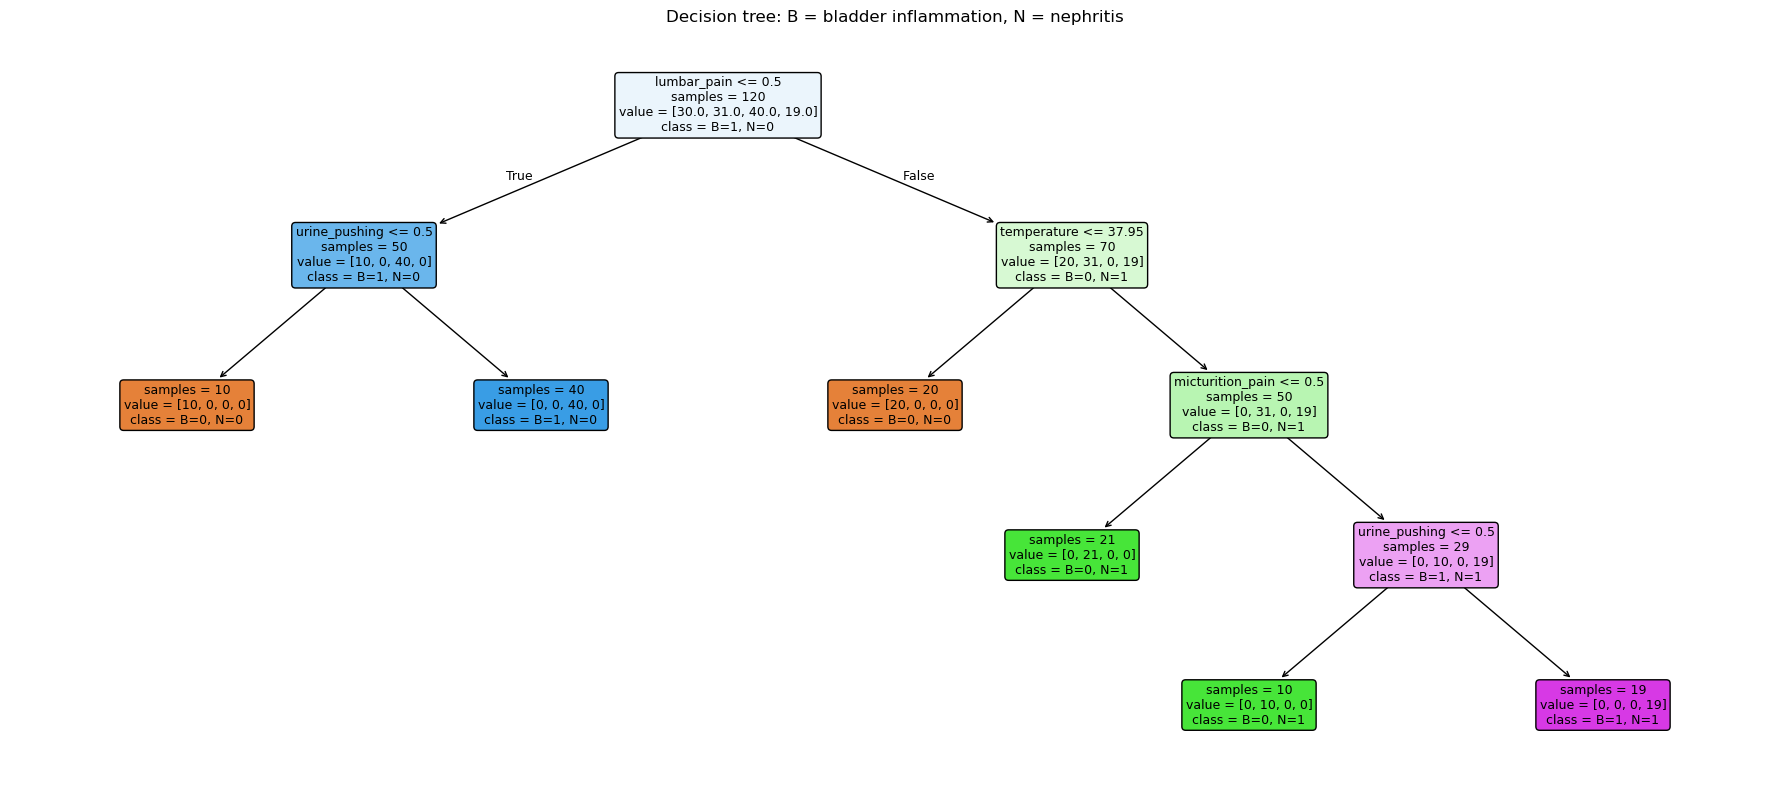

In [19]:
full_tree = DecisionTreeClassifier(random_state=seed).fit(X_act, y_act)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(full_tree, feature_names=X_act.columns.tolist(),
          class_names=full_tree.classes_.tolist(), filled=True, rounded=True,
          impurity=False, fontsize=9, ax=ax)
ax.set_title('Decision tree: B = bladder inflammation, N = nephritis')
plt.tight_layout()
plt.show()


### (c) Convert the decision rules

In [ ]:
# Code is from: https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html

def tree_to_pseudo(tree, feature_names):
    """Print IF/THEN pseudocode using the linked article's recursive traversal."""
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] if i != _tree.TREE_UNDEFINED else None
                for i in tree.tree_.feature]
    value = tree.tree_.value

    def recurse(left, right, threshold, features, node, depth=0):
        indent = "  " * depth
        if tree.tree_.feature[node] != _tree.TREE_UNDEFINED:
            print(indent, "IF ( " + features[node] + " <= " + str(threshold[node]) + " ) THEN {")
            if left[node] != -1:
                recurse(left, right, threshold, features, left[node], depth+1)
                print(indent, "} ELSE {")
                if right[node] != -1:
                    recurse(left, right, threshold, features, right[node], depth+1)
                print(indent, "}")
        else:
            diagnosis = tree.classes_[int(np.argmax(value[node][0]))]
            print(indent, "RETURN " + str(diagnosis))

    recurse(left, right, threshold, features, 0)

tree_to_pseudo(full_tree, X_act.columns.tolist())


 IF ( lumbar_pain <= 0.5 ) THEN {
   IF ( urine_pushing <= 0.5 ) THEN {
     RETURN B=0, N=0
   } ELSE {
     RETURN B=1, N=0
   }
 } ELSE {
   IF ( temperature <= 37.95000076293945 ) THEN {
     RETURN B=0, N=0
   } ELSE {
     IF ( micturition_pain <= 0.5 ) THEN {
       RETURN B=0, N=1
     } ELSE {
       IF ( urine_pushing <= 0.5 ) THEN {
         RETURN B=0, N=1
       } ELSE {
         RETURN B=1, N=1
       }
     }
   }
 }


# (d) Cost-Complexity Pruning

In [ ]:
path = full_tree.cost_complexity_pruning_path(X_act, y_act)
prune_alpha = path.ccp_alphas[path.ccp_alphas > 0][0]
pruned = DecisionTreeClassifier(random_state=seed, ccp_alpha=prune_alpha).fit(X_act, y_act)
print(f'alpha: {prune_alpha}')
print(f'tree: {pruned.get_n_leaves()} leaves, depth: {pruned.get_depth()}')
tree_to_pseudo(pruned, X_act.columns.tolist())


alpha: 0.098167
tree: 4 leaves, depth: 2
 IF ( lumbar_pain <= 0.5 ) THEN {
   IF ( urine_pushing <= 0.5 ) THEN {
     RETURN B=0, N=0
   } ELSE {
     RETURN B=1, N=0
   }
 } ELSE {
   IF ( temperature <= 37.95000076293945 ) THEN {
     RETURN B=0, N=0
   } ELSE {
     RETURN B=0, N=1
   }
 }


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [22]:
description = (DATA / 'communities.names').read_text()
column_names = re.findall(r'^@attribute\s+(\S+)', description, flags=re.MULTILINE)
communities = pd.read_csv(DATA / 'communities.data', header=None,
                          names=column_names, na_values='?')
target = 'ViolentCrimesPerPop'
remove = ['state', 'county', 'community', 'communityname', 'fold']
X = communities.drop(columns=remove + [target]).astype(float)
y = communities[target].astype(float)
X_train, X_test = X.iloc[:1495].copy(), X.iloc[1495:].copy()
y_train, y_test = y.iloc[:1495].copy(), y.iloc[1495:].copy()


### (b) Missing values

In [ ]:
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns,
                               index=X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)


### (c) Plot a correlation matrix

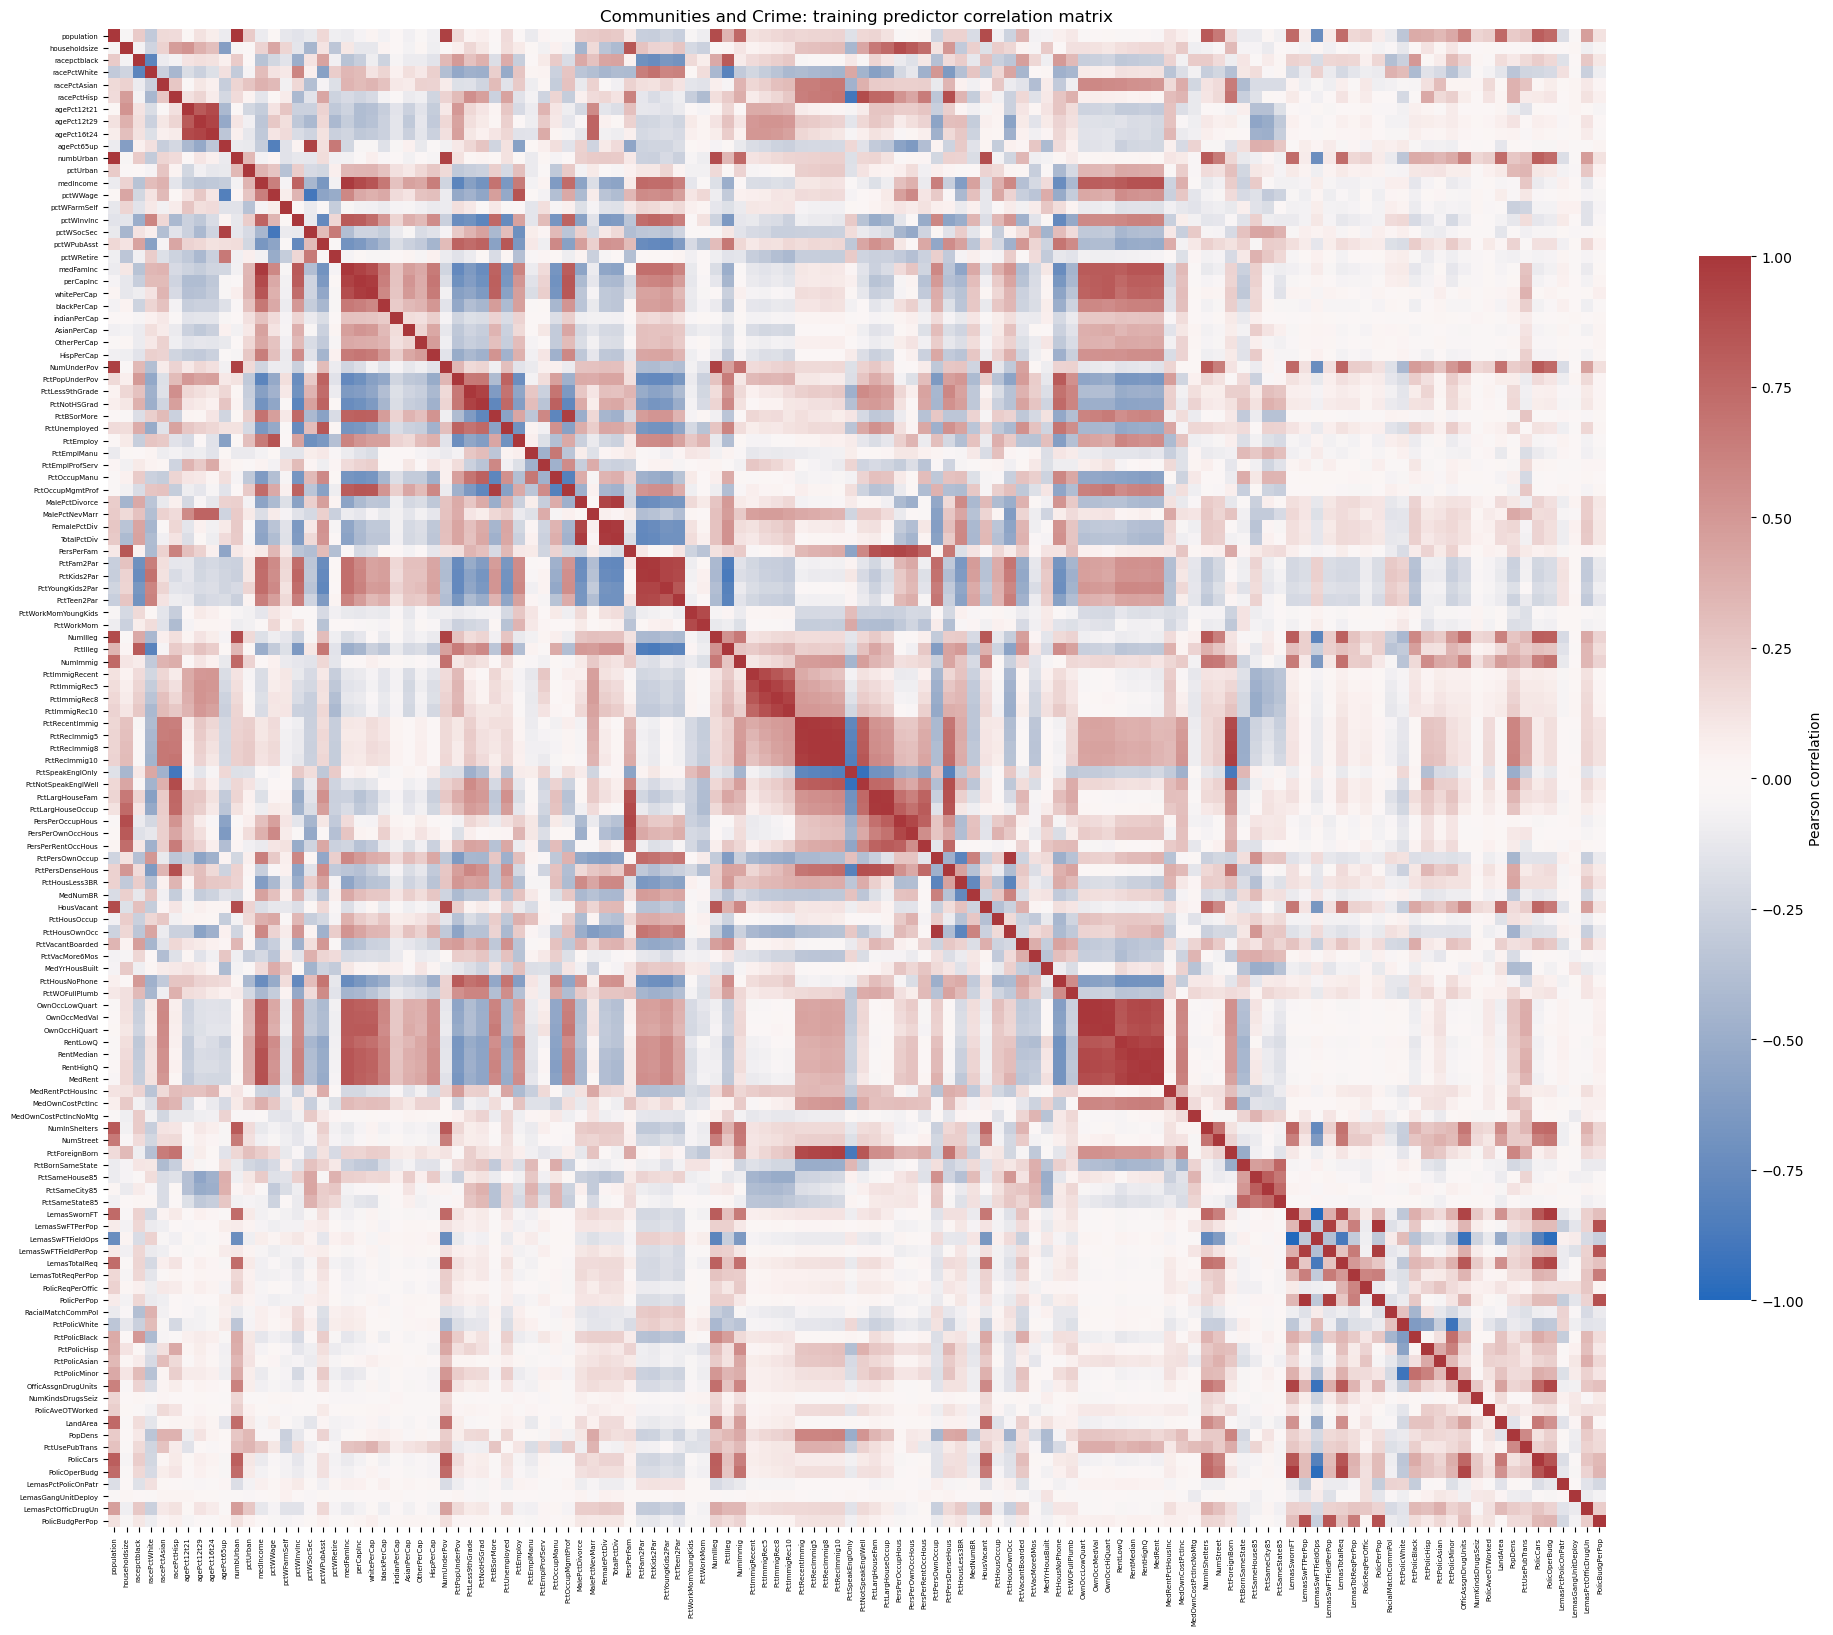

In [24]:
correlation = X_train_imputed.corr()
fig, ax = plt.subplots(figsize=(20, 17))
sns.heatmap(correlation, cmap='vlag', center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, square=True,
            cbar_kws={'label': 'Pearson correlation', 'shrink': .65}, ax=ax)
ax.tick_params(axis='both', labelsize=5)
plt.setp(ax.get_xticklabels(), rotation=90)
plt.setp(ax.get_yticklabels(), rotation=0)
ax.set_title('Communities and Crime: training predictor correlation matrix')
plt.tight_layout()
plt.show()


### (d) Calculate the Coefficient of Variation CV

In [25]:
feature_mean = X_train_imputed.mean()
feature_sd = X_train_imputed.std(ddof=1)
variation = pd.DataFrame({'coefficient_of_variation':
                         feature_sd / feature_mean.replace(0, np.nan)})
variation = variation.sort_values('coefficient_of_variation', ascending=False)
display(variation)


,coefficient_of_variation
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
...,...
NumKindsDrugsSeiz,0.141021
RacialMatchCommPol,0.129652
PctPolicWhite,0.118727
LemasPctPolicOnPatr,0.112032


### (e) Scatter plots and box plots for highest CV features

From the scatter plots it looks like the features are very significant from the vertical line that most of them form. Despite this to know for sure the significance of the features, a statistical test would need to be done.

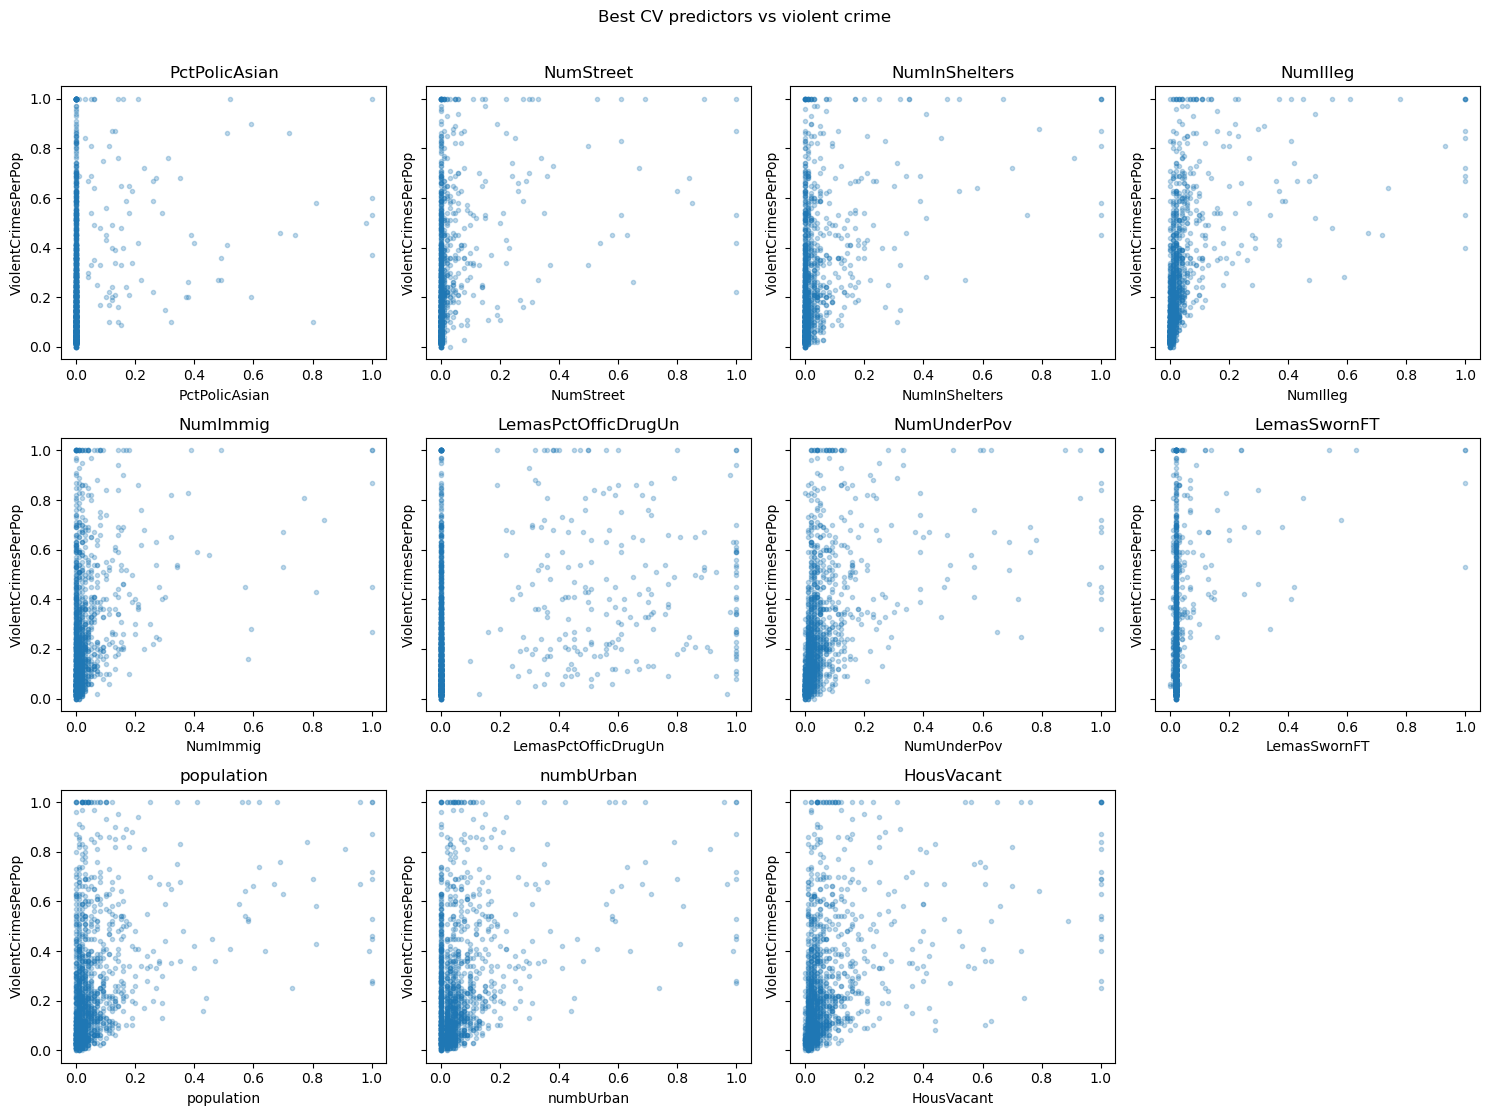

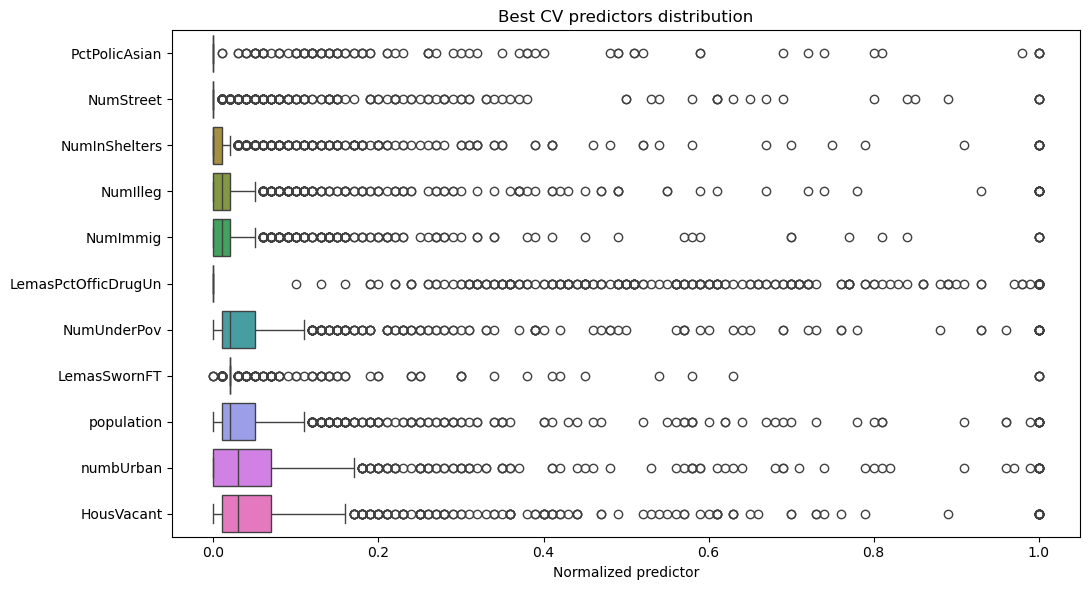

In [26]:
n = int(np.floor(np.sqrt(128)))
top_cv_features = variation.coefficient_of_variation.dropna().head(n).index.tolist()
fig, axs = plt.subplots(3, 4, figsize=(15, 11), sharey=True)
for feature, ax in zip(top_cv_features, axs.flat):
    ax.scatter(X_train_imputed[feature], y_train, s=9, alpha=.28)
    ax.set(title=feature, xlabel=feature, ylabel=target)
for ax in axs.flat[n:]:
    ax.set_visible(False)
fig.suptitle('Best CV predictors vs violent crime', y=1.01)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=X_train_imputed[top_cv_features], orient='h', ax=ax)
ax.set(title='Best CV predictors distribution', xlabel='Normalized predictor')
plt.tight_layout()
plt.show()


### (f) Fit a linear model

In [27]:
ols = Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('model', LinearRegression())])
ols.fit(X_train, y_train)
ols_mse = mean_squared_error(y_test, ols.predict(X_test))
print(f'Least-squares test MSE: {ols_mse:.6f}')


Least-squares test MSE: 0.017966


### (g) Fit a ridge regression model

In [28]:
regression_cv = KFold(n_splits=5, shuffle=True, random_state=seed)
ridge_pipeline = Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                           ('scale', StandardScaler()), ('model', Ridge())])
ridge_search = GridSearchCV(ridge_pipeline,
                            {'model__alpha': np.logspace(-4, 4, 33)},
                            cv=regression_cv, scoring='neg_mean_squared_error', n_jobs=1)
ridge_search.fit(X_train, y_train)
print('Selected ridge alpha:', ridge_search.best_params_['model__alpha'])
ridge_mse = mean_squared_error(y_test, ridge_search.predict(X_test))
print(f'Ridge test MSE: {ridge_mse:.6f}')


Selected ridge alpha: 56.23413251903491
Ridge test MSE: 0.017475


### (h) Fit a LASSO model

In [29]:
results = []
for standardized in [False, True]:
    name = 'Standardized' if standardized else 'Without standardization'
    steps = [('impute', SimpleImputer(strategy='median', keep_empty_features=True))]
    if standardized:
        steps.append(('scale', StandardScaler()))
    steps.append(('model', Lasso(max_iter=50000, tol=1e-4)))
    search = GridSearchCV(Pipeline(steps),
                           {'model__alpha': np.logspace(-5, -1, 25)},
                           cv=regression_cv, scoring='neg_mean_squared_error', n_jobs=1)
    search.fit(X_train, y_train)
    selected = X.columns[search.best_estimator_.named_steps['model'].coef_ != 0].tolist()
    mse = mean_squared_error(y_test, search.predict(X_test))
    print(name)
    print('alpha:', search.best_params_['model__alpha'])
    print(f'Test MSE: {mse}')
    print(f'Selected variables: {selected}')


Without standardization
alpha: 0.0001
Test MSE: 0.01765867644581908
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'Num

The test error of both are very close but the model without standardization is lower. This means that standardizing the features made the model less accurate. 

### (i) Fit a PCR model

In [30]:
pcr_pipeline = Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                         ('scale', StandardScaler()), ('pca', PCA(svd_solver='full')),
                         ('model', LinearRegression())])
pcr_search = GridSearchCV(pcr_pipeline,
                          {'pca__n_components': list(range(1, X_train.shape[1] + 1))},
                          cv=regression_cv, scoring='neg_mean_squared_error', n_jobs=1)
pcr_search.fit(X_train, y_train)
print('Selected number of components M:', pcr_search.best_params_['pca__n_components'])
pcr_mse = mean_squared_error(y_test, pcr_search.predict(X_test))
print(f'PCR test MSE: {pcr_mse}')


Selected number of components M: 93
PCR test MSE: 0.01826424604513008


### (j) Fit a boosting tree

In [31]:
pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('model', XGBRegressor(objective='reg:squarederror', booster='gbtree',
                           n_estimators=400, learning_rate=.05, max_depth=3,
                           subsample=.8, colsample_bytree=.8, reg_lambda=1.,
                           tree_method='hist', n_jobs=1, random_state=seed))])
search = GridSearchCV(pipeline,
                            {'model__reg_alpha': [0., 1e-4, 1e-3, 1e-2, .1, 1., 10., 100.]},
                            cv=regression_cv, scoring='neg_mean_squared_error', n_jobs=1)
search.fit(X_train, y_train)
print(f'L1 alpha: {search.best_params_['model__reg_alpha']}')


L1 alpha: 1.0
